# Analysis: CO2, Energy and Temperature (US & Canada focus)
Run this after the three cleaning notebooks. It reads `data/merged_final.csv` and `data/energy_breakdown_final.csv` and saves charts to `images/`.

Units in the source data: CO2 in million tonnes (Mt), energy in quadrillion BTU, GDP in billions of US dollars, population in thousands.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)

merged = pd.read_csv("data/merged_final.csv")
breakdown = pd.read_csv("data/energy_breakdown_final.csv")
breakdown["year"] = pd.to_datetime(breakdown["year"]).dt.year

# Per-person and per-GDP measures
merged["co2_per_person_t"] = merged["co2_emission"] * 1000 / merged["population"]     # tonnes per person
merged["energy_per_gdp"] = merged["energy_consumption"] * 1000 / merged["gdp"]        # thousand BTU per dollar

FOCUS = ["United States", "Canada"]

In [2]:
# Chart style: one consistent look for every chart
US, CA = "#2a78d6", "#eb6834"                 # colour follows the country in every chart
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def label_end(ax, x, y, text, color, dy=0):
    """Direct label at the end of a line, in text colour next to a coloured dot.
    dy nudges the label up/down (in points) when two lines end close together."""
    ax.plot([x], [y], "o", color=color, ms=6)
    ax.annotate(text, (x, y), xytext=(8, dy), textcoords="offset points", va="center", color=INK, fontsize=10)

## 1. Global CO2 emissions
CO2 coverage is only near-complete from 1993 (see `MERGED_DATASET.ipynb`), so the global trend starts there.

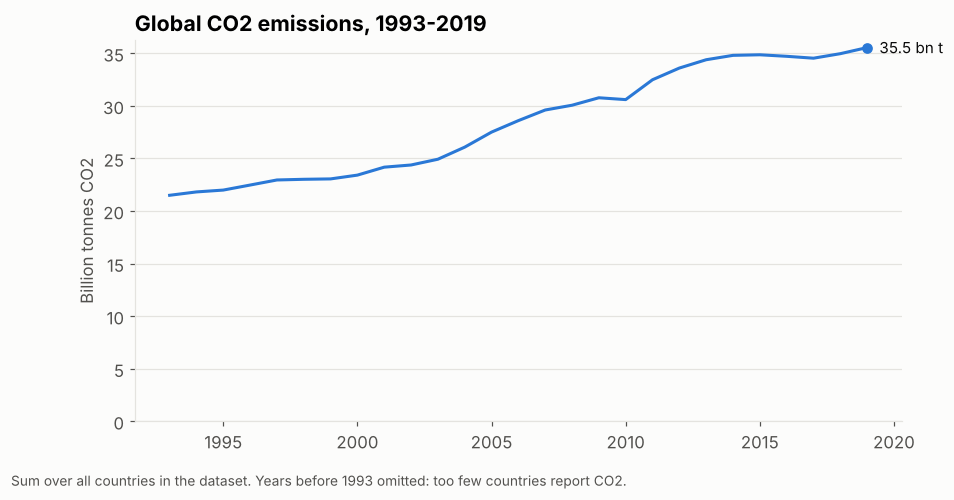

Change 1993-2019: +65%


In [3]:
coverage = merged.groupby("year")["co2_emission"].apply(lambda s: (s > 0).sum())
complete = coverage[coverage >= 0.9 * coverage.max()].index
world = merged[merged["year"].isin(complete)].groupby("year")["co2_emission"].sum() / 1000   # billion tonnes

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(world.index, world.values, color=US)
label_end(ax, world.index[-1], world.values[-1], f"{world.values[-1]:.1f} bn t", US)
ax.set_title("Global CO2 emissions, 1993-2019")
ax.set_ylabel("Billion tonnes CO2")
ax.set_ylim(0, None)
fig.text(0.0, -0.02, "Sum over all countries in the dataset. Years before 1993 omitted: too few countries report CO2.", color=MUTED, fontsize=9)
fig.savefig("images/global_co2.png")
plt.show()
print(f"Change 1993-2019: {world.iloc[-1] / world.iloc[0] - 1:+.0%}")

## 2. US vs Canada: emissions per person
Total emissions favour big countries. Per person, the US and Canada are much closer.

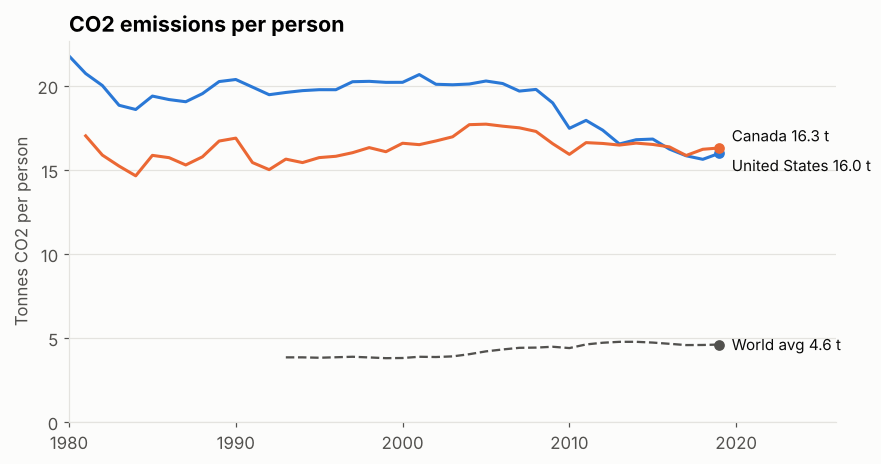

country,Canada,United States
year,,
1981,17.0,20.7
2000,16.6,20.2
2007,17.5,19.7
2019,16.3,16.0


In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for country, color, dy in [("United States", US, -8), ("Canada", CA, 8)]:
    d = merged[(merged["country"] == country) & merged["co2_per_person_t"].notna()]
    ax.plot(d["year"], d["co2_per_person_t"], color=color)
    label_end(ax, d["year"].iloc[-1], d["co2_per_person_t"].iloc[-1],
              f"{country} {d['co2_per_person_t'].iloc[-1]:.1f} t", color, dy)

world_pp = (merged[merged["year"].isin(complete)].groupby("year")
            .apply(lambda g: g["co2_emission"].sum() * 1000 / g["population"].sum()))
ax.plot(world_pp.index, world_pp.values, color=MUTED, lw=1.5, ls="--")
label_end(ax, world_pp.index[-1], world_pp.values[-1], f"World avg {world_pp.values[-1]:.1f} t", MUTED)

ax.set_title("CO2 emissions per person")
ax.set_ylabel("Tonnes CO2 per person")
ax.set_ylim(0, None)
ax.set_xlim(1980, 2026)
fig.savefig("images/co2_per_person_us_canada.png")
plt.show()

pp = merged[merged["country"].isin(FOCUS)].pivot(index="year", columns="country", values="co2_per_person_t")
pp.loc[[1981, 2000, 2007, 2019]].round(1)

## 3. US vs Canada: energy efficiency of the economy
Energy used per dollar of GDP. Lower means the economy produces more output from each unit of energy.

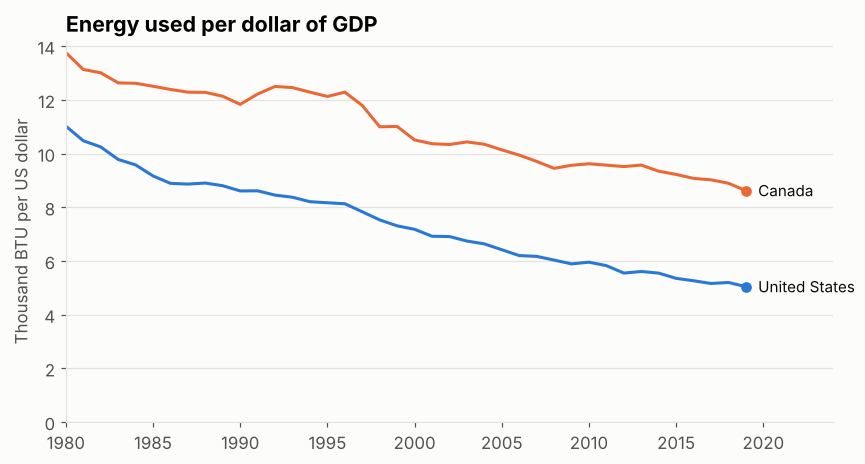

Change in energy per dollar of GDP, 1980-2019:
country
Canada           -37%
United States    -54%
dtype: str


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for country, color in [("United States", US), ("Canada", CA)]:
    d = merged[merged["country"] == country]
    ax.plot(d["year"], d["energy_per_gdp"], color=color)
    label_end(ax, d["year"].iloc[-1], d["energy_per_gdp"].iloc[-1], country, color)
ax.set_title("Energy used per dollar of GDP")
ax.set_ylabel("Thousand BTU per US dollar")
ax.set_ylim(0, None)
ax.set_xlim(1980, 2024)
fig.savefig("images/energy_intensity_us_canada.png")
plt.show()

ei = merged[merged["country"].isin(FOCUS)].pivot(index="year", columns="country", values="energy_per_gdp")
print("Change in energy per dollar of GDP, 1980-2019:")
print((ei.loc[2019] / ei.loc[1980] - 1).map("{:+.0%}".format))

## 4. US vs Canada: where the energy comes from
Share of energy consumption by source, 1990 vs 2019. Canada's large hydro sector shows up under renewables.

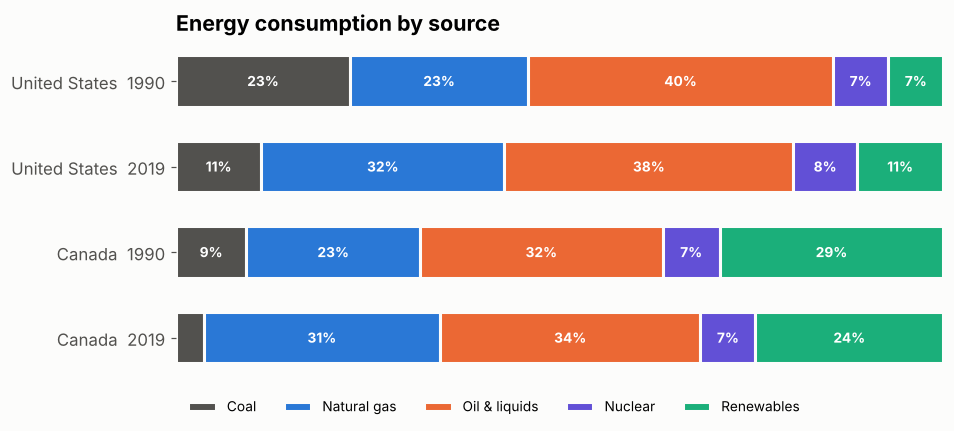

energy_type         coal  natural_gas  petroleum_n_other_liquids  nuclear  \
country       year                                                          
United States 1990  22.7         23.2                       39.7      7.2   
              2019  11.1         31.7                       37.7      8.3   
Canada        1990   9.2         22.7                       31.6      7.5   
              2019   3.6         30.8                       33.9      7.2   

energy_type         renewables_n_other  
country       year                      
United States 1990                 7.1  
              2019                11.2  
Canada        1990                29.1  
              2019                24.5

In [6]:
SOURCES = ["coal", "natural_gas", "petroleum_n_other_liquids", "nuclear", "renewables_n_other"]
NAMES = {"coal": "Coal", "natural_gas": "Natural gas", "petroleum_n_other_liquids": "Oil & liquids",
         "nuclear": "Nuclear", "renewables_n_other": "Renewables"}
COLORS = ["#52514e", "#2a78d6", "#eb6834", "#6250d6", "#1baf7a"]   # fixed order

mix = (breakdown[breakdown["country"].isin(FOCUS) & breakdown["year"].isin([1990, 2019])
                 & breakdown["energy_type"].isin(SOURCES)]
       .pivot_table(index=["country", "year"], columns="energy_type", values="energy_consumption")[SOURCES])
share = mix.div(mix.sum(axis=1), axis=0) * 100
share = share.loc[[("United States", 1990), ("United States", 2019), ("Canada", 1990), ("Canada", 2019)]]

fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{c}  {y}" for c, y in share.index]
left = np.zeros(len(share))
for src, color in zip(SOURCES, COLORS):
    vals = share[src].values
    ax.barh(labels, vals, left=left, color=color, height=0.6, edgecolor=SURFACE, linewidth=2, label=NAMES[src])
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_xticks([])
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Energy consumption by source")
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.02), frameon=False, fontsize=9)
fig.savefig("images/energy_mix_us_canada.png")
plt.show()
share.round(1)

## 5. Temperature in the US and Canada
Annual mean temperature with a straight-line trend (faint line = actual yearly values).

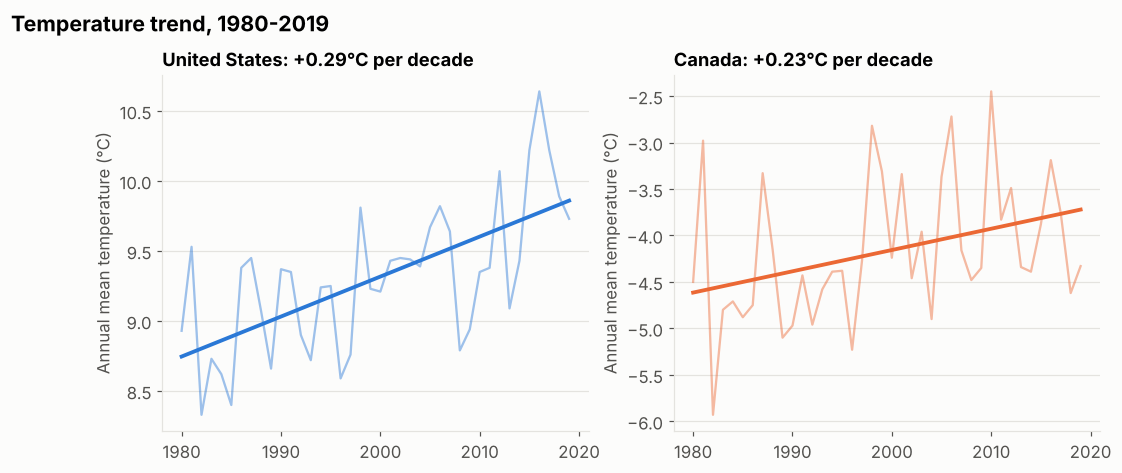

{'United States': np.float64(0.29), 'Canada': np.float64(0.23)}

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
trends = {}
for ax, (country, color) in zip(axes, [("United States", US), ("Canada", CA)]):
    d = merged[(merged["country"] == country) & merged["annual_mean"].notna()]
    slope, intercept = np.polyfit(d["year"], d["annual_mean"], 1)
    trends[country] = slope * 10
    ax.plot(d["year"], d["annual_mean"], color=color, lw=1.5, alpha=0.45)
    ax.plot(d["year"], intercept + slope * d["year"], color=color, lw=2.5)
    ax.set_title(f"{country}: {slope * 10:+.2f}°C per decade", fontsize=12)
    ax.set_ylabel("Annual mean temperature (°C)")
fig.suptitle("Temperature trend, 1980-2019", x=0.0, ha="left", fontweight="bold", fontsize=14, y=1.02)
fig.savefig("images/temperature_us_canada.png")
plt.show()
{k: round(v, 2) for k, v in trends.items()}

## 6. Do high-emitting countries warm faster?
For each country with temperature data: CO2 per person (average 1993-2019) against its own warming rate (1980-2019).

CO2 mixes around the whole planet, so a country's own emissions shouldn't directly set its own warming. But colder, higher-latitude countries tend to both emit more per person and warm faster, so the chart is checked again after accounting for each country's average temperature.

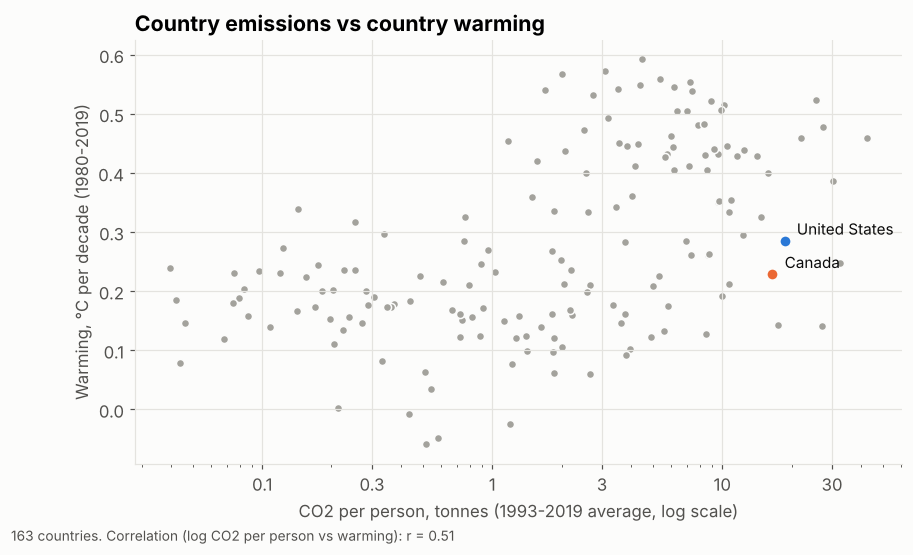

Countries: 163, r = 0.51
Average temperature vs warming: r = -0.60 (colder countries warm faster)
Emissions vs warming after accounting for average temperature: r = 0.35


In [8]:
rows = []
for country, d in merged.dropna(subset=["annual_mean"]).groupby("country"):
    if len(d) < 30:
        continue
    warming = np.polyfit(d["year"], d["annual_mean"], 1)[0] * 10
    recent = d[d["year"] >= 1993]
    co2pp = recent["co2_emission"].sum() * 1000 / recent["population"].sum()
    rows.append({"country": country, "warming_per_decade": warming, "co2_per_person": co2pp})
by_country = pd.DataFrame(rows).dropna()
by_country = by_country[by_country["co2_per_person"] > 0]

r = np.corrcoef(np.log10(by_country["co2_per_person"]), by_country["warming_per_decade"])[0, 1]

fig, ax = plt.subplots(figsize=(9, 5))
other = by_country[~by_country["country"].isin(FOCUS)]
ax.scatter(other["co2_per_person"], other["warming_per_decade"], s=28, color="#a3a29c", edgecolor=SURFACE, linewidth=1)
for country, color in [("United States", US), ("Canada", CA)]:
    p = by_country[by_country["country"] == country].iloc[0]
    ax.scatter(p["co2_per_person"], p["warming_per_decade"], s=70, color=color, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(country, (p["co2_per_person"], p["warming_per_decade"]), xytext=(8, 4),
                textcoords="offset points", color=INK, fontsize=10)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.3, 1, 3, 10, 30])
ax.set_xticklabels(["0.1", "0.3", "1", "3", "10", "30"])
ax.grid(True, axis="both")
ax.set_xlabel("CO2 per person, tonnes (1993-2019 average, log scale)")
ax.set_ylabel("Warming, °C per decade (1980-2019)")
ax.set_title("Country emissions vs country warming")
fig.text(0.0, -0.03, f"{len(by_country)} countries. Correlation (log CO2 per person vs warming): r = {r:.2f}", color=MUTED, fontsize=9)
fig.savefig("images/emissions_vs_warming.png")
plt.show()
print(f"Countries: {len(by_country)}, r = {r:.2f}")

# Account for climate: colder countries warm faster AND emit more.
# Remove the part of each variable explained by average temperature, then correlate what's left.
avg_temp = merged.dropna(subset=["annual_mean"]).groupby("country")["annual_mean"].mean()
by_country["avg_temp"] = by_country["country"].map(avg_temp)
def residual(y, x):
    return y - np.polyval(np.polyfit(x, y, 1), x)
r_temp = np.corrcoef(by_country["avg_temp"], by_country["warming_per_decade"])[0, 1]
r_partial = np.corrcoef(residual(by_country["warming_per_decade"], by_country["avg_temp"]),
                        residual(np.log10(by_country["co2_per_person"]), by_country["avg_temp"]))[0, 1]
print(f"Average temperature vs warming: r = {r_temp:.2f} (colder countries warm faster)")
print(f"Emissions vs warming after accounting for average temperature: r = {r_partial:.2f}")

## Summary
- Global CO2 rose about 65% from 1993 to 2019.
- Per person, the US fell from about 21 to 16 tonnes; Canada stayed between about 15 and 18 tonnes, so by 2019 the two were level.
- Both economies use much less energy per dollar of GDP than in 1980 (US -54%, Canada -37%).
- Both cut coal sharply since 1990 and shifted toward natural gas; Canada gets far more of its energy from renewables (mostly hydro).
- Both countries warmed by roughly 0.2-0.3°C per decade.
- Countries that emit more per person warmed somewhat faster, but much of that is because colder countries both emit more and warm faster. Accounting for climate weakens the link (r 0.51 -> 0.35), and it remains a correlation, not proof of cause.